In [2]:
from google.colab import files

uploaded = files.upload()

Saving student-mat.csv to student-mat.csv


In [3]:
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


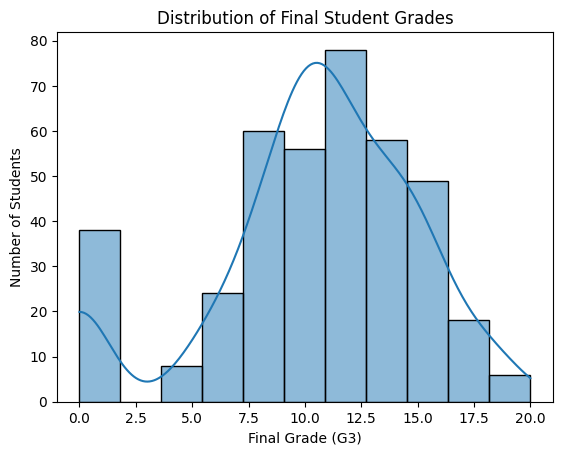

In [4]:

# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Visualize final grade distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x="G3", bins=11, kde=True)
plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features and target output
X = df.drop("G3", axis=1)
y = df["G3"]

# Convert categorical data into numerical data
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Normalize input features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data preprocessing completed successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Input features:", X_train.shape[1])
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Data preprocessing completed successfully!
Training samples: 316
Testing samples: 79
Input features: 41
Training target shape: (316,)
Testing target shape: (79,)


In [6]:

import tensorflow as tf

# Build the MLP model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),

    # First hidden layer
    tf.keras.layers.Dense(64, activation="relu"),

    # Second hidden layer
    tf.keras.layers.Dense(32, activation="relu"),

    # Output layer for predicting final grades
    tf.keras.layers.Dense(1, activation="linear")
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,801 (18.75 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("MLP model training completed successfully!")

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 123.0103 - mae: 10.1281 - val_loss: 106.7794 - val_mae: 9.6128
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 96.4554 - mae: 8.9713 - val_loss: 81.6184 - val_mae: 8.4218
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 69.5902 - mae: 7.6221 - val_loss: 55.5742 - val_mae: 6.9017
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 43.8787 - mae: 5.9580 - val_loss: 31.7259 - val_mae: 5.0433
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 24.2593 - mae: 4.2124 - val_loss: 16.9219 - val_mae: 3.5285
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 13.9616 - mae: 2.9847 - val_loss: 11.9666 - val_mae: 2.8293
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 10.4744 - mae: 2.4388 - val_loss: 10.1389 - val_mae: 2.5237
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2908 - mae: 2.1470 - val_loss: 9.0675 - val_mae: 2.3886
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/

In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict grades for test data
y_pred = model.predict(X_test).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("MLP MODEL EVALUATION")
print("--------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score: {r2:.3f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
MLP MODEL EVALUATION
--------------------
Mean Absolute Error (MAE): 2.19
Mean Squared Error (MSE): 8.12
Root Mean Squared Error (RMSE): 2.85
R2 Score: 0.604


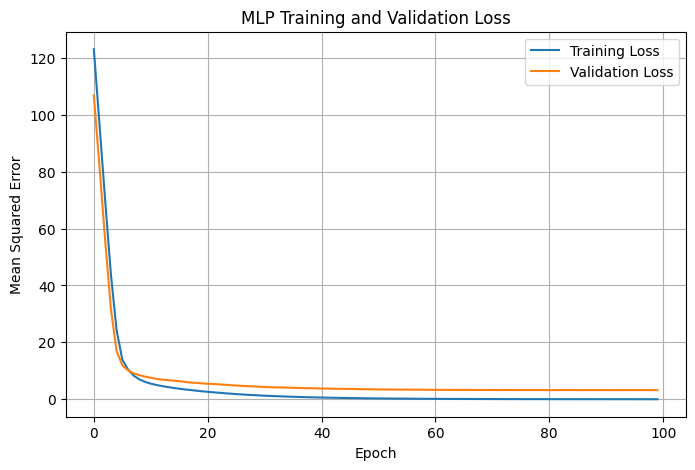

In [9]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()


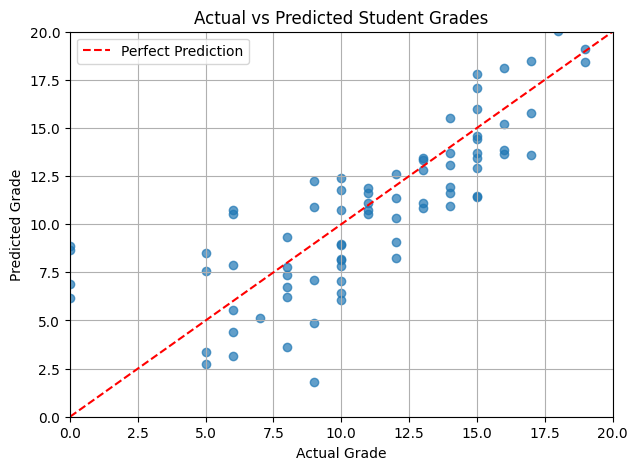

In [10]:

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([0, 20], [0, 20], "r--", label="Perfect Prediction")
plt.title("Actual vs Predicted Student Grades")
plt.xlabel("Actual Grade")
plt.ylabel("Predicted Grade")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.legend()
plt.grid(True)
plt.show()


In [11]:

results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": np.round(y_pred, 2)
})

results["Absolute Error"] = np.round(
    np.abs(results["Actual Grade"] - results["Predicted Grade"]), 2
)

display(results.head(10))


,Actual Grade,Predicted Grade,Absolute Error
0,10,8.900000,1.10
1,12,11.340000,0.66
2,5,2.750000,2.25
3,10,11.760000,1.76
4,9,12.240000,3.24
5,13,11.110000,1.89
6,18,20.030001,2.03
7,6,10.550000,4.55
8,0,8.650000,8.65
9,14,11.930000,2.07


In [12]:

# Save the trained MLP model
model.save("student_performance_mlp.keras")

print("Model saved successfully!")


Model saved successfully!


In [13]:

# Additional Experiment: MLP Classification of Student Grades
# Original regression model remains unchanged.

import tensorflow as tf
import numpy as np
import pandas as pd

# Convert numerical grades into 3 categories:
# Low: 0-9, Medium: 10-14, High: 15-20

grade_bins = [-1, 9, 14, 20]
grade_labels = [0, 1, 2]

y_train_class = pd.cut(
    y_train, bins=grade_bins, labels=grade_labels
).astype(int)

y_test_class = pd.cut(
    y_test, bins=grade_bins, labels=grade_labels
).astype(int)

print("Training class distribution:")
print(y_train_class.value_counts().sort_index().rename(
    index={0: "Low", 1: "Medium", 2: "High"}
))

# Build a separate classification model
clf_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

# Compile the classifier
clf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

clf_model.summary()

# Train the classifier using the existing training features
clf_history = clf_model.fit(
    X_train,
    y_train_class,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("Additional MLP classification experiment completed!")


Training class distribution:
G3
Low       103
Medium    160
High       53
Name: count, dtype: int64


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,867 (19.01 KB)

 Trainable params: 4,867 (19.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.4603 - loss: 1.0838 - val_accuracy: 0.5156 - val_loss: 0.9806
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5794 - loss: 0.9197 - val_accuracy: 0.5625 - val_loss: 0.9296
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6468 - loss: 0.8169 - val_accuracy: 0.5312 - val_loss: 0.8877
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7262 - loss: 0.7293 - val_accuracy: 0.5469 - val_loss: 0.8430
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7698 - loss: 0.6514 - val_accuracy: 0.5625 - val_loss: 0.8059
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8135 - loss: 0.5760 - val_accuracy: 0.5781 - val_loss: 0.7658
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8452 - loss: 0.5096 - val_accuracy: 0.5781 - val_loss: 0.7227
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8810 - loss: 0.4469 - val_accuracy: 0.6094 - 

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


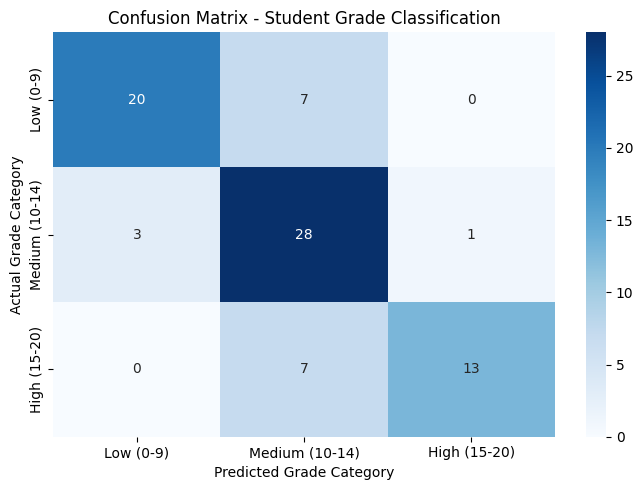

Classification Accuracy: 0.7722

Classification Report:
              precision    recall  f1-score   support

         Low       0.87      0.74      0.80        27
      Medium       0.67      0.88      0.76        32
        High       0.93      0.65      0.76        20

    accuracy                           0.77        79
   macro avg       0.82      0.76      0.77        79
weighted avg       0.80      0.77      0.77        79



In [14]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict class probabilities and select the most likely class
class_probabilities = clf_model.predict(X_test)
y_class_pred = np.argmax(class_probabilities, axis=1)

# Actual test classes
y_class_true = y_test_class.to_numpy()

# Calculate confusion matrix
cm = confusion_matrix(
    y_class_true, y_class_pred, labels=[0, 1, 2]
)

# Display confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low (0-9)", "Medium (10-14)", "High (15-20)"],
    yticklabels=["Low (0-9)", "Medium (10-14)", "High (15-20)"]
)

plt.title("Confusion Matrix - Student Grade Classification")
plt.xlabel("Predicted Grade Category")
plt.ylabel("Actual Grade Category")
plt.tight_layout()
plt.show()

# Calculate classification metrics
print("Classification Accuracy:",
      round(accuracy_score(y_class_true, y_class_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_class_true,
    y_class_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"],
    zero_division=0
))


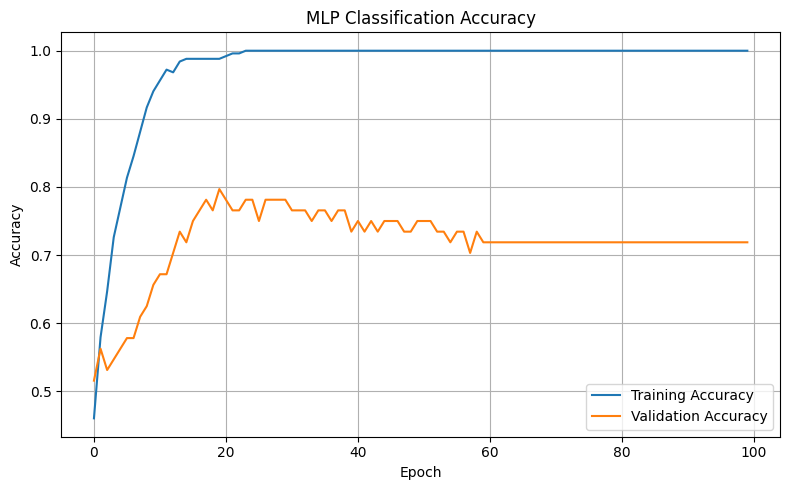

In [15]:

plt.figure(figsize=(8, 5))
plt.plot(clf_history.history["accuracy"], label="Training Accuracy")
plt.plot(clf_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("MLP Classification Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [16]:

from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_class_true,
    y_class_pred,
    labels=[0, 1, 2],
    target_names=["Low (0-9)", "Medium (10-14)", "High (15-20)"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose().round(3)

display(report_df)

print("Classification experiment completed.")


,precision,recall,f1-score,support
Low (0-9),0.870,0.741,0.800,27.000
Medium (10-14),0.667,0.875,0.757,32.000
High (15-20),0.929,0.650,0.765,20.000
accuracy,0.772,0.772,0.772,0.772
macro avg,0.822,0.755,0.774,79.000
weighted avg,0.802,0.772,0.774,79.000


Classification experiment completed.
